In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50

In [2]:
import os

dataset_path = "caltech-101"

print(os.listdir(dataset_path)[:10])

['.ipynb_checkpoints', 'accordion', 'airplanes', 'anchor', 'ant', 'BACKGROUND_Google', 'barrel', 'bass', 'beaver', 'binocular']


In [3]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)

Found 7356 images belonging to 103 classes.
Found 1788 images belonging to 103 classes.


In [4]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

In [5]:
base_model.trainable = False

In [6]:
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(train_data.num_classes, activation="softmax")
])

In [7]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    train_data,
    epochs=1,
    validation_data=val_data,
    verbose=1
)

230/230 ━━━━━━━━━━━━━━━━━━━━ 971s 4s/step - accuracy: 0.2855 - loss: 3.4082 - val_accuracy: 0.4597 - val_loss: 2.5443


In [9]:
train_loss = history.history['loss'][-1]
val_loss = history.history['val_loss'][-1]

print("Training Loss:", train_loss)
print("Validation Loss:", val_loss)

Training Loss: 3.408170223236084
Validation Loss: 2.5443058013916016


In [10]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

56/56 ━━━━━━━━━━━━━━━━━━━━ 186s 3s/step - accuracy: 0.4597 - loss: 2.5443
Validation Loss: 2.5443058013916016
Validation Accuracy: 0.4597315490245819


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


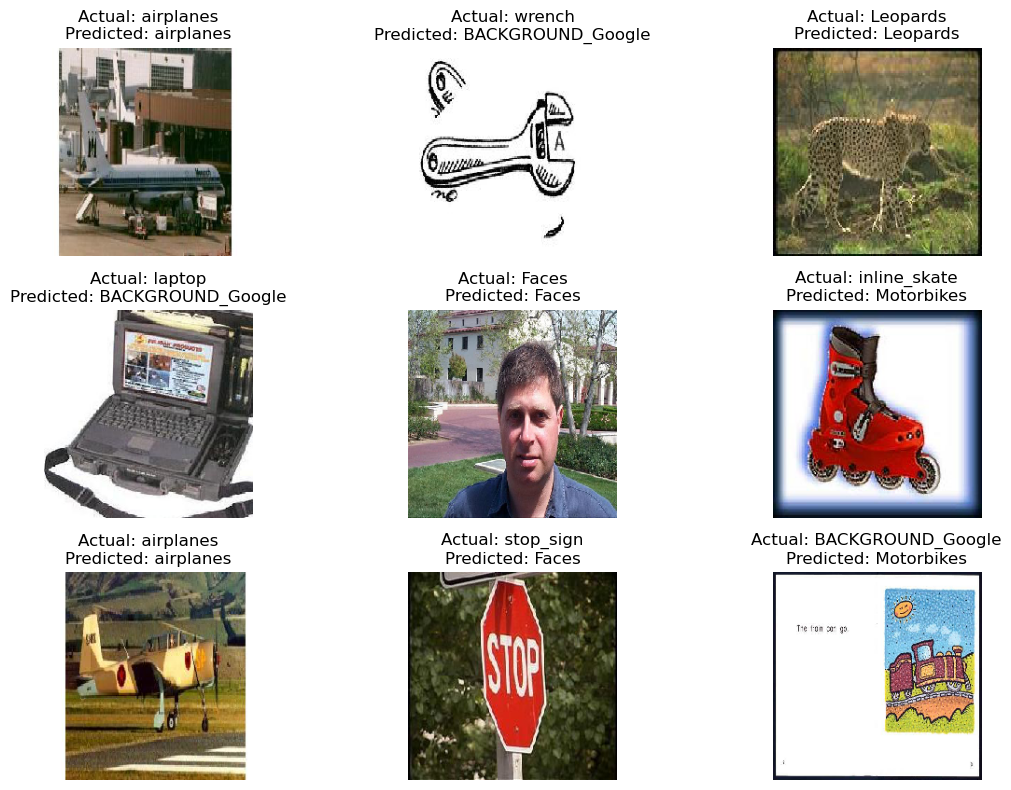

In [11]:
images, true_labels = next(val_data)

predictions = model.predict(images)

predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(true_labels, axis=1)

class_names = list(val_data.class_indices.keys())

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i])

    plt.title(
        f"Actual: {class_names[actual_classes[i]]}\n"
        f"Predicted: {class_names[predicted_classes[i]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
base_model.trainable = True

for layer in base_model.layers[:-4]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
history_fine = model.fit(
    train_data,
    epochs=1,
    validation_data=val_data,
    verbose=1
)

230/230 ━━━━━━━━━━━━━━━━━━━━ 1180s 5s/step - accuracy: 0.5150 - loss: 2.0583 - val_accuracy: 0.5912 - val_loss: 1.7472
